In [3]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Load dataset
df = pd.read_csv("fakenews.csv")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display dataset
print(df[["label", "text"]].head())

print("\nTotal articles:", len(df))
print("Dataset loaded successfully!")

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...

Total articles: 2212
Dataset loaded successfully!


In [4]:
# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=1000
)

# Calculate TF-IDF matrix
tfidf_matrix = vectorizer.fit_transform(df["text"])

# Get all words
words = vectorizer.get_feature_names_out()

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Total unique words selected:", len(words))

TF-IDF matrix shape: (2212, 98)
Total unique words selected: 98


In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# Calculate Term Frequency (TF)
tf_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    vocabulary=words
)

tf_matrix = tf_vectorizer.fit_transform(df["text"])

# Calculate total term frequency across the dataset
total_tf = tf_matrix.sum(axis=0).A1

# Get IDF values
idf_values = vectorizer.idf_

# Calculate average TF-IDF for each word
average_tfidf = tfidf_matrix.mean(axis=0).A1

# Create a results DataFrame
tf_idf_df = pd.DataFrame({
    "Word": words,
    "Total_TF": total_tf,
    "IDF": idf_values,
    "Average_TF_IDF": average_tfidf
})

# Display the 20 most frequent words
print("TF, IDF and TF-IDF Values:")
print(
    tf_idf_df.sort_values(
        by="Total_TF",
        ascending=False
    ).head(20)
)

TF, IDF and TF-IDF Values:
             Word  Total_TF       IDF  Average_TF_IDF
58            new       643  2.234406        0.063040
10     bangladesh       478  2.530404        0.055261
33        experts       448  2.595081        0.052382
37     government       390  2.764568        0.045629
24            cup       252  3.168715        0.036598
94           wins       252  3.168715        0.036598
96          world       252  3.168715        0.036598
52          media       240  3.217307        0.033572
79         social       240  3.217307        0.033572
60           noon       240  3.217307        0.033572
59           news       240  3.217307        0.033572
93           went       240  3.217307        0.033572
90          viral       240  3.217307        0.033572
1     advancement       232  3.251066        0.035011
87  technological       232  3.251066        0.035011
77    significant       232  3.251066        0.035011
13        believe       232  3.251066        0.035011
1

In [6]:
# Calculate TF-IDF values separately for Real and Fake news
for label in df["label"].dropna().unique():

    # Select articles belonging to the current label
    label_indices = df.index[df["label"] == label]

    # Calculate average TF-IDF for each word
    label_tfidf = tfidf_matrix[label_indices].mean(axis=0).A1

    # Create a DataFrame of word importance
    label_words = pd.DataFrame({
        "Word": words,
        "Average_TF_IDF": label_tfidf
    })

    # Display the top 10 important words
    top_words = label_words.sort_values(
        by="Average_TF_IDF",
        ascending=False
    ).head(10)

    print(f"\nTop 10 Important Words in {label} News:")
    print(top_words)


Top 10 Important Words in Real News:
          Word  Average_TF_IDF
58         new        0.065877
10  bangladesh        0.055460
33     experts        0.050439
37  government        0.043265
24         cup        0.041438
94        wins        0.041438
96       world        0.041438
32       event        0.038533
21       claim        0.038533
95   witnessed        0.038533

Top 10 Important Words in Fake News:
            Word  Average_TF_IDF
58           new        0.060223
10    bangladesh        0.055063
33       experts        0.054311
37    government        0.047976
7   authenticity        0.040350
42      incident        0.040350
72       remains        0.040350
88   uncertainty        0.040350
86          tech        0.038431
14  breakthrough        0.038431


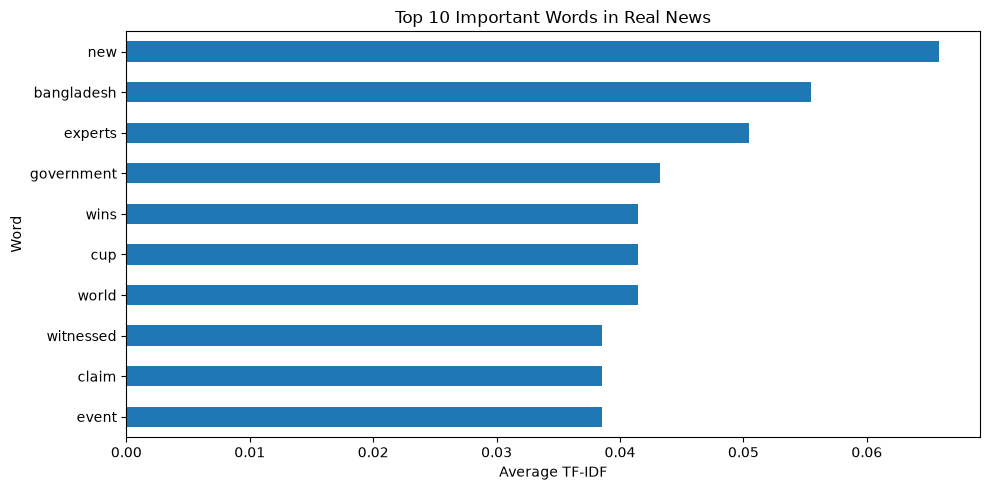

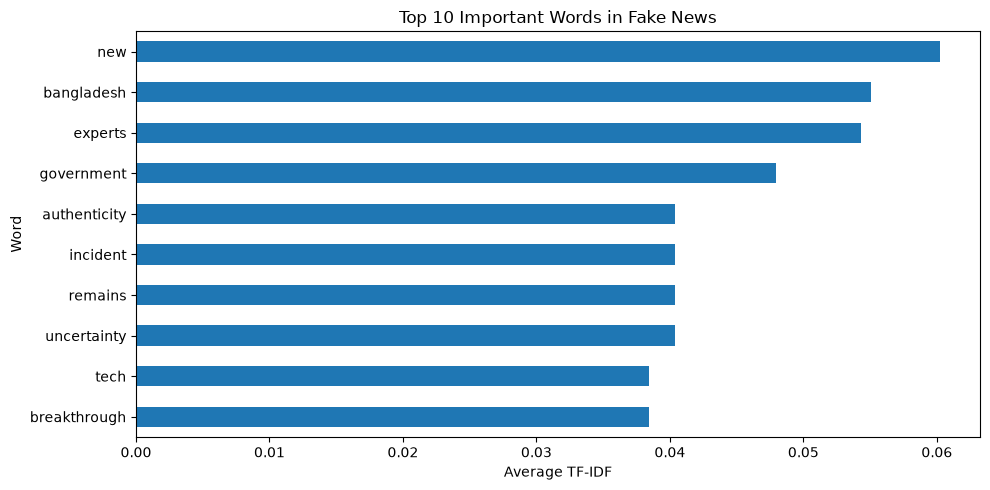

In [7]:
# Plot top 10 important words for Real and Fake news
for label in df["label"].dropna().unique():

    label_indices = df.index[df["label"] == label]
    label_tfidf = tfidf_matrix[label_indices].mean(axis=0).A1

    label_words = pd.DataFrame({
        "Word": words,
        "Average_TF_IDF": label_tfidf
    })

    top_words = label_words.sort_values(
        by="Average_TF_IDF",
        ascending=False
    ).head(10)

    plt.figure(figsize=(10, 5))

    top_words.sort_values(
        by="Average_TF_IDF"
    ).plot(
        x="Word",
        y="Average_TF_IDF",
        kind="barh",
        legend=False,
        ax=plt.gca()
    )

    plt.title(f"Top 10 Important Words in {label} News")
    plt.xlabel("Average TF-IDF")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()

In [1]:
# Save TF, IDF and TF-IDF values
tf_idf_df.to_csv("T16_tf_idf_values.csv", index=False)

# Save top important words separately for each label
for label in df["label"].dropna().unique():

    label_indices = df.index[df["label"] == label]
    label_tfidf = tfidf_matrix[label_indices].mean(axis=0).A1

    label_words = pd.DataFrame({
        "Word": words,
        "Average_TF_IDF": label_tfidf
    })

    top_words = label_words.sort_values(
        by="Average_TF_IDF",
        ascending=False
    ).head(10)

    top_words.to_csv(
        f"T16_top_words_{label}.csv",
        index=False
    )

print("Task 16 completed successfully!")
print("1. T16_tf_idf_values.csv")
print("2. T16_top_words_Real.csv")
print("3. T16_top_words_Fake.csv")


NameError: name 'tf_idf_df' is not defined